# RDR2 Sentiment Analysis — Visual Export

Generates the matplotlib charts used in the PowerPoint deck and as a reference for the Power BI report, from the aggregated CSVs produced in `02_sentiment_analysis.ipynb`.

**Note on this version:** the epilogue effect chart was moved from Q3 to Q1 — it's a content finding (epilogue-mentioning vs. non-epilogue reviews), not a time-based one, so it belongs with the other chapter-impact analysis rather than under "sentiment over time." Q3 now includes the patch-date correlation attempt instead, which is genuinely time-based even though its conclusion is inconclusive.

**Depends on:** all CSVs produced by `02_sentiment_analysis.ipynb`.
**Outputs:** PNG charts saved to `charts/`.


In [1]:
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import requests
import os

# Download the western display font (one-time; skips re-download if already present)
os.makedirs("../fonts", exist_ok=True)
rye_path = "../fonts/Rye-Regular.ttf"

if not os.path.exists(rye_path):
    r = requests.get("https://raw.githubusercontent.com/google/fonts/main/ofl/rye/Rye-Regular.ttf")
    with open(rye_path, "wb") as f:
        f.write(r.content)

fm.fontManager.addfont(rye_path)
title_font = fm.FontProperties(fname=rye_path)

# Color palette
COLOR_BG = "#1A1A1A"
COLOR_PRIMARY = "#A4113C"
COLOR_ACCENT = "#ED254E"
COLOR_DARK_ACCENT = "#002A32"
COLOR_TEXT = "#F2F2F2"

plt.rcParams["figure.facecolor"] = COLOR_BG
plt.rcParams["axes.facecolor"] = COLOR_BG
plt.rcParams["axes.edgecolor"] = COLOR_TEXT
plt.rcParams["text.color"] = COLOR_TEXT
plt.rcParams["axes.labelcolor"] = COLOR_TEXT
plt.rcParams["xtick.color"] = COLOR_TEXT
plt.rcParams["ytick.color"] = COLOR_TEXT
plt.rcParams["font.family"] = "DejaVu Serif"

os.makedirs("../charts", exist_ok=True)

df_chapters = pd.read_csv("../data/processed/chapters_sentiment.csv")
df_missions = pd.read_csv("../data/processed/missions_sentiment.csv")
df_characters = pd.read_csv("../data/processed/characters_sentiment.csv")
df_yearly = pd.read_csv("../data/processed/sentiment_over_time_yearly.csv")
df_comparison = pd.read_csv("../data/processed/comparison_rdr2_gtav.csv")
df_trends_summary = pd.read_csv("../data/processed/comparison_trends_summary.csv")
df_patch_effects = pd.read_csv("../data/processed/sentiment_patch_effects.csv")

print("Font registered:", fm.FontProperties(fname=rye_path).get_name())
print("Setup complete.")

Font registered: Rye
Setup complete.


# Question 1: Which missions/chapters had the most emotional impact vs. cultural staying power?

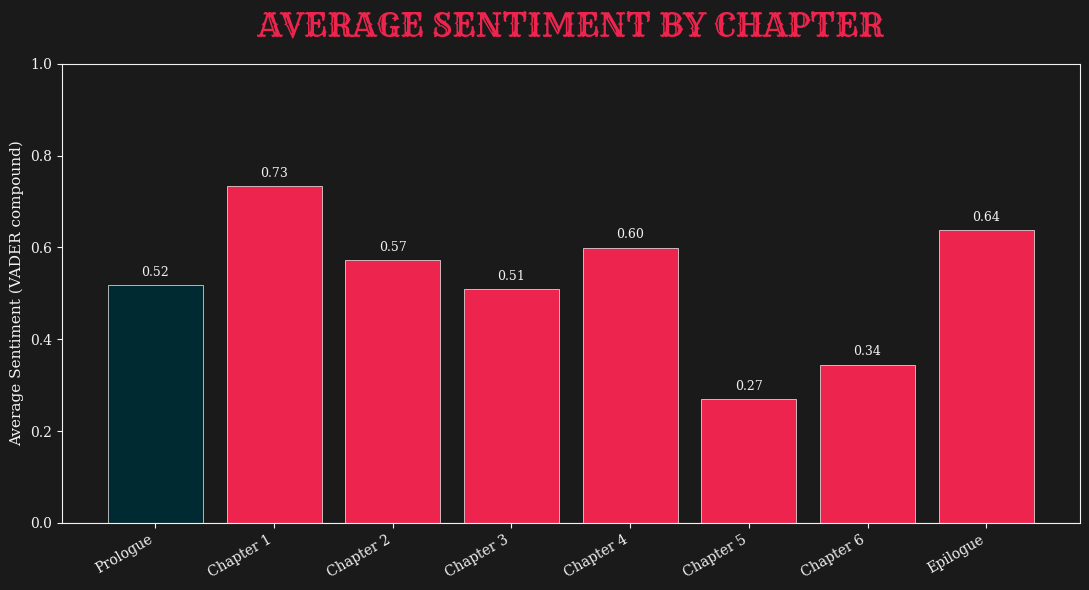

In [2]:
import numpy as np

# Ensure chapters are in story order, not sorted by mention count
chapter_order = ["Prologue", "Chapter 1", "Chapter 2", "Chapter 3", "Chapter 4", "Chapter 5", "Chapter 6", "Epilogue"]
df_chapters_ordered = df_chapters.set_index("entity_name").loc[chapter_order].reset_index()

# --- Chart 1: Average sentiment by chapter ---
fig, ax = plt.subplots(figsize=(11, 6))

colors = [COLOR_ACCENT if conf == False else COLOR_DARK_ACCENT for conf in df_chapters_ordered["low_confidence"]]
bars = ax.bar(df_chapters_ordered["entity_name"], df_chapters_ordered["avg_sentiment"], color=colors, edgecolor=COLOR_TEXT, linewidth=0.5)

ax.set_title("AVERAGE SENTIMENT BY CHAPTER", fontproperties=title_font, fontsize=24, color=COLOR_ACCENT, pad=20)
ax.set_ylabel("Average Sentiment (VADER compound)", fontsize=11)
ax.set_xlabel("")
ax.axhline(0, color=COLOR_TEXT, linewidth=0.8, alpha=0.5)
plt.xticks(rotation=30, ha="right", fontsize=10)
ax.set_ylim(0, 1)

for bar, val in zip(bars, df_chapters_ordered["avg_sentiment"]):
    ax.text(bar.get_x() + bar.get_width()/2, val + 0.02, f"{val:.2f}", ha="center", fontsize=9, color=COLOR_TEXT)

plt.tight_layout()
plt.savefig("../charts/q1_chapter_avg_sentiment.png", dpi=300, facecolor=fig.get_facecolor())
plt.show()

## Average Sentiment by Chapter
**Chapter 1 scores highest of any chapter (0.73 avg sentiment)**, likely reflecting the excitement of a fresh start, with the Epilogue close behind (0.64). Chapter 5/Guarma dips lowest (0.27), consistent with fan consensus that the Guarma detour is the story's weakest stretch. Prologue is flagged low-confidence (only 19 mentions, below the 20-mention reliability threshold).

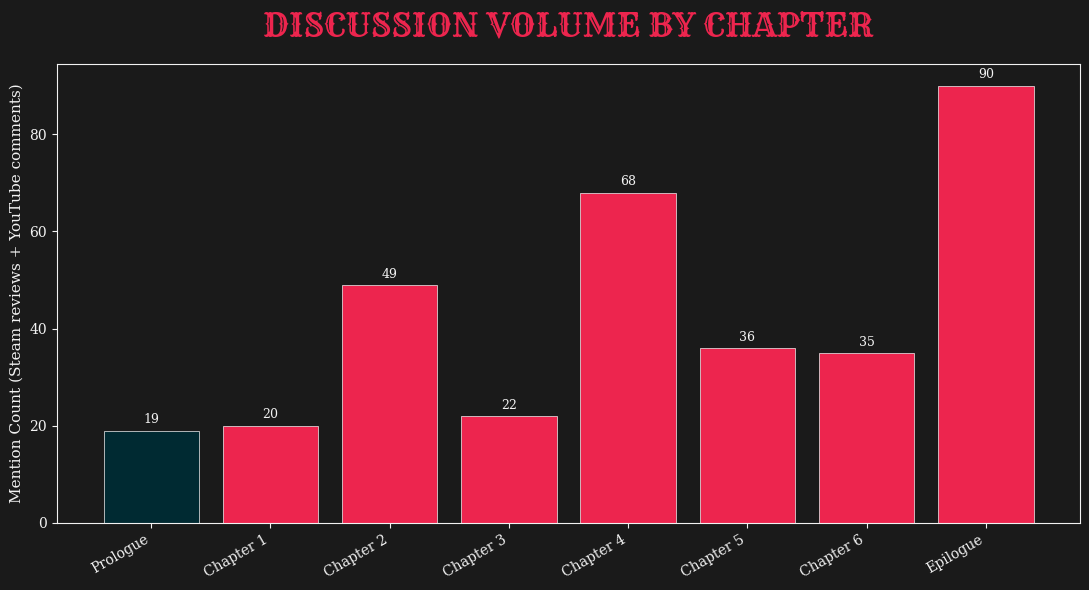

In [3]:
# --- Chart 2: Mention volume by chapter (updated for color consistency) ---
fig, ax = plt.subplots(figsize=(11, 6))

colors = [COLOR_ACCENT if conf == False else COLOR_DARK_ACCENT for conf in df_chapters_ordered["low_confidence"]]
bars = ax.bar(df_chapters_ordered["entity_name"], df_chapters_ordered["mention_count"], color=colors, edgecolor=COLOR_TEXT, linewidth=0.5)

ax.set_title("DISCUSSION VOLUME BY CHAPTER", fontproperties=title_font, fontsize=24, color=COLOR_ACCENT, pad=20)
ax.set_ylabel("Mention Count (Steam reviews + YouTube comments)", fontsize=11)
ax.set_xlabel("")
plt.xticks(rotation=30, ha="right", fontsize=10)

for bar, val in zip(bars, df_chapters_ordered["mention_count"]):
    ax.text(bar.get_x() + bar.get_width()/2, val + 1.5, f"{int(val)}", ha="center", fontsize=9, color=COLOR_TEXT)

plt.tight_layout()
plt.savefig("../charts/q1_chapter_mentions.png", dpi=300, facecolor=fig.get_facecolor())
plt.show()

## Discussion Volume by Chapter
**The Epilogue is the most-discussed chapter overall** (90 mentions), even though it ranks second in sentiment behind Chapter 1. High volume despite not topping sentiment is itself notable — players return to and discuss the Epilogue more than any other chapter, evidence of its outsized cultural footprint even though it isn't the single most positively received part of the story.

`Note`: mission-level analysis (not charted) was also attempted, but 23 of 24 curated missions fell below the reliability threshold — players discuss RDR2 through characters and chapters, not named missions. Worth stating as a finding in itself if you want to reference it in the deck.

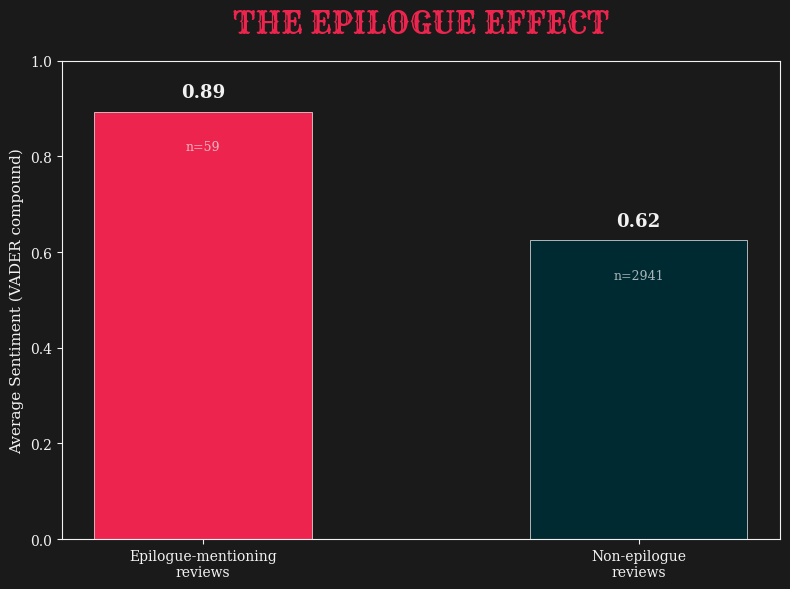

In [4]:
epilogue_data = pd.DataFrame({
    "group": ["Epilogue-mentioning\nreviews", "Non-epilogue\nreviews"],
    "avg_sentiment": [0.8937135593220339, 0.6244925195511731],
    "count": [59, 2941]
})

fig, ax = plt.subplots(figsize=(8, 6))
bars = ax.bar(epilogue_data["group"], epilogue_data["avg_sentiment"], color=[COLOR_ACCENT, COLOR_DARK_ACCENT], edgecolor=COLOR_TEXT, linewidth=0.5, width=0.5)

ax.set_title("THE EPILOGUE EFFECT", fontproperties=title_font, fontsize=22, color=COLOR_ACCENT, pad=20)
ax.set_ylabel("Average Sentiment (VADER compound)", fontsize=11)
ax.set_ylim(0, 1)

for bar, val, n in zip(bars, epilogue_data["avg_sentiment"], epilogue_data["count"]):
    ax.text(bar.get_x() + bar.get_width()/2, val + 0.03, f"{val:.2f}", ha="center", fontsize=13, color=COLOR_TEXT, weight="bold")
    ax.text(bar.get_x() + bar.get_width()/2, val - 0.08, f"n={n}", ha="center", fontsize=9, color=COLOR_TEXT, alpha=0.7)

plt.tight_layout()
plt.savefig("../charts/q1_epilogue_effect.png", dpi=300, facecolor=fig.get_facecolor())
plt.show()

## The Epilogue Effect
A closer look at *why* the Epilogue scores as high as it does: reviews that specifically mention the epilogue average 0.89 sentiment vs. 0.62 for reviews that don't (n=59 vs. n=2,941) — a large, statistically comfortable gap. Manually spot-checked a sample of the epilogue-mentioning reviews to rule out duplication/viral-copy artifacts; confirmed genuine, varied reviews. This is one of the strongest, cleanest findings in the whole project, and reinforces the chapter-level result above: the Epilogue isn't just discussed often, the specific reviews that engage with it skew strongly positive.

Later reproduced as a row-level export (`rdr2_epilogue_mention_flag.csv`) so it could be rebuilt natively in Power BI rather than only existing as this static summary.

# Question 2: Which characters are most loved, hated, or polarizing?

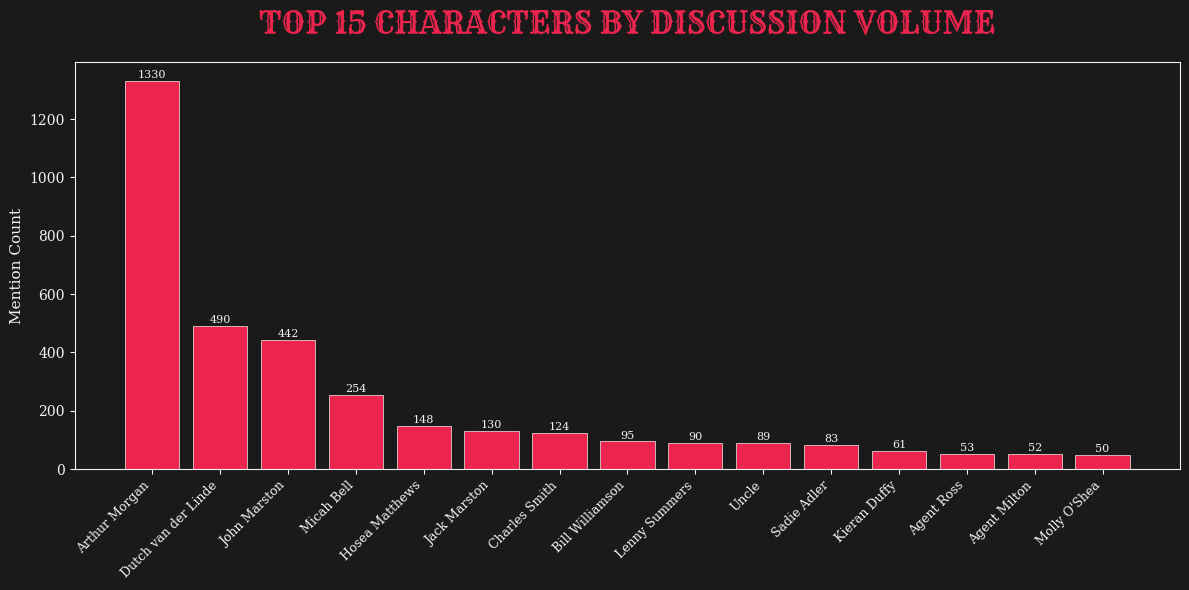

In [5]:
# --- Chart 1: Top 15 characters by mention volume ---
df_char_sorted = df_characters.sort_values("mention_count", ascending=False).head(15)

fig, ax = plt.subplots(figsize=(12, 6))
colors = [COLOR_ACCENT if conf == False else COLOR_DARK_ACCENT for conf in df_char_sorted["low_confidence"]]
bars = ax.bar(df_char_sorted["entity_name"], df_char_sorted["mention_count"], color=colors, edgecolor=COLOR_TEXT, linewidth=0.5)

ax.set_title("TOP 15 CHARACTERS BY DISCUSSION VOLUME", fontproperties=title_font, fontsize=22, color=COLOR_ACCENT, pad=20)
ax.set_ylabel("Mention Count", fontsize=11)
plt.xticks(rotation=45, ha="right", fontsize=9)

for bar, val in zip(bars, df_char_sorted["mention_count"]):
    ax.text(bar.get_x() + bar.get_width()/2, val + 10, f"{int(val)}", ha="center", fontsize=8, color=COLOR_TEXT)

plt.tight_layout()
plt.savefig("../charts/q2_character_mentions.png", dpi=300, facecolor=fig.get_facecolor())
plt.show()

## Top 15 Characters by Discussion Volume
Arthur Morgan dominates (1,330 mentions — over a third of all character mentions combined) as the protagonist, followed by Dutch (490) and John Marston (442). Micah Bell ranks fourth (254) despite being the antagonist rather than a gang member — the central conflict gets discussed almost as much as the central relationships. Beyond the top three, volume drops off sharply: only 7 of 25 characters clear 100 mentions.

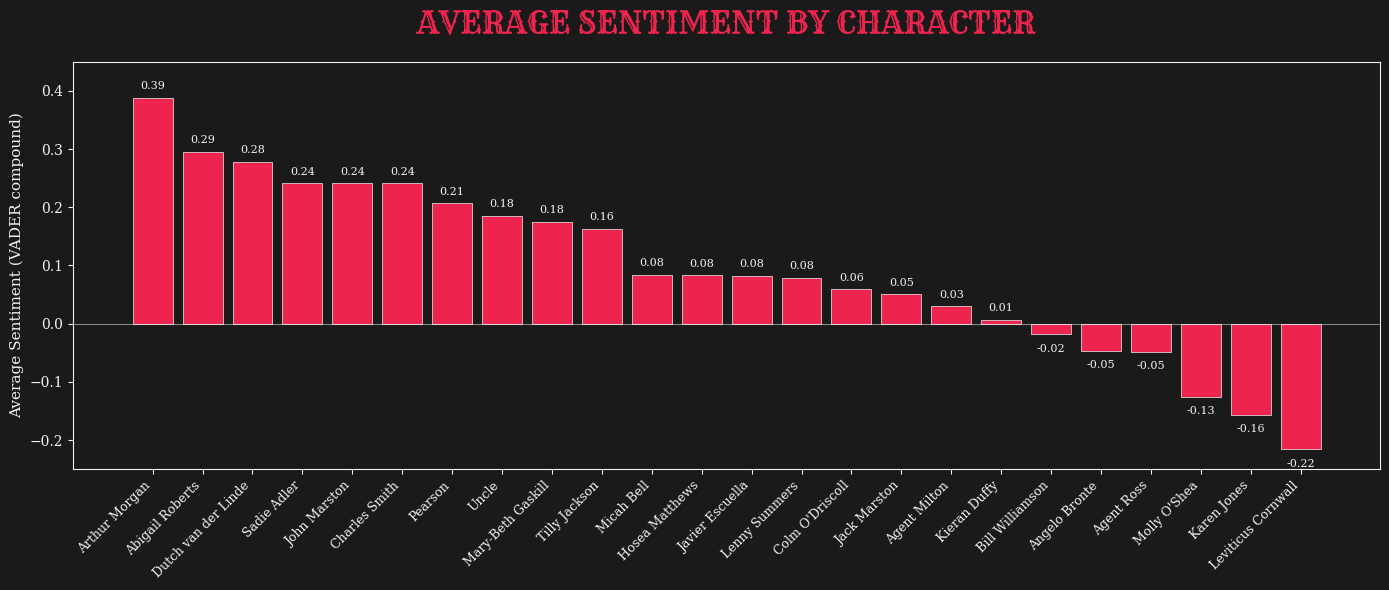

In [6]:
# Fix for Chart 2: full character set (not just top-15 by volume), 
# filtered to the 20-mention reliability threshold, sorted by sentiment
df_char_sentiment_full = df_characters[df_characters["mention_count"] >= 20].sort_values("avg_sentiment", ascending=False)

fig, ax = plt.subplots(figsize=(14, 6))
colors = [COLOR_ACCENT if conf == False else COLOR_DARK_ACCENT for conf in df_char_sentiment_full["low_confidence"]]
bars = ax.bar(df_char_sentiment_full["entity_name"], df_char_sentiment_full["avg_sentiment"], color=colors, edgecolor=COLOR_TEXT, linewidth=0.5)

ax.set_title("AVERAGE SENTIMENT BY CHARACTER", fontproperties=title_font, fontsize=22, color=COLOR_ACCENT, pad=20)
ax.set_ylabel("Average Sentiment (VADER compound)", fontsize=11)
ax.axhline(0, color=COLOR_TEXT, linewidth=0.8, alpha=0.5)
ax.set_ylim(-0.25, 0.45)
plt.xticks(rotation=45, ha="right", fontsize=9)

for bar, val in zip(bars, df_char_sentiment_full["avg_sentiment"]):
    y_pos = val + 0.015 if val >= 0 else val - 0.03
    ax.text(bar.get_x() + bar.get_width()/2, y_pos, f"{val:.2f}", ha="center", fontsize=8, color=COLOR_TEXT)

plt.tight_layout()
plt.savefig("../charts/q2_character_avg_sentiment.png", dpi=300, facecolor=fig.get_facecolor())
plt.show()

## Average Sentiment by Character
Arthur leads in positive sentiment (0.39), followed by a broad tier of well-liked characters — Abigail Roberts (0.29), Dutch (0.28), Sadie Adler (0.24), and John Marston (0.24) — none dominating the way Arthur does in mention volume.

**Among the game's most-discussed characters, Molly O'Shea (-0.13) scores lowest**, ahead of Agent Ross (-0.05) and Bill Williamson (-0.02). But looking at the full character set (all entities clearing the 20-mention threshold), **Leviticus Cornwall (-0.22) and Karen Jones (-0.16) both score more negatively than Molly** — lower-volume figures whose sentiment is more extreme but who fall outside the most-discussed core cast. Micah Bell — the story's primary antagonist — sits at a near-neutral 0.08, suggesting complex/mixed reactions rather than pure hatred.

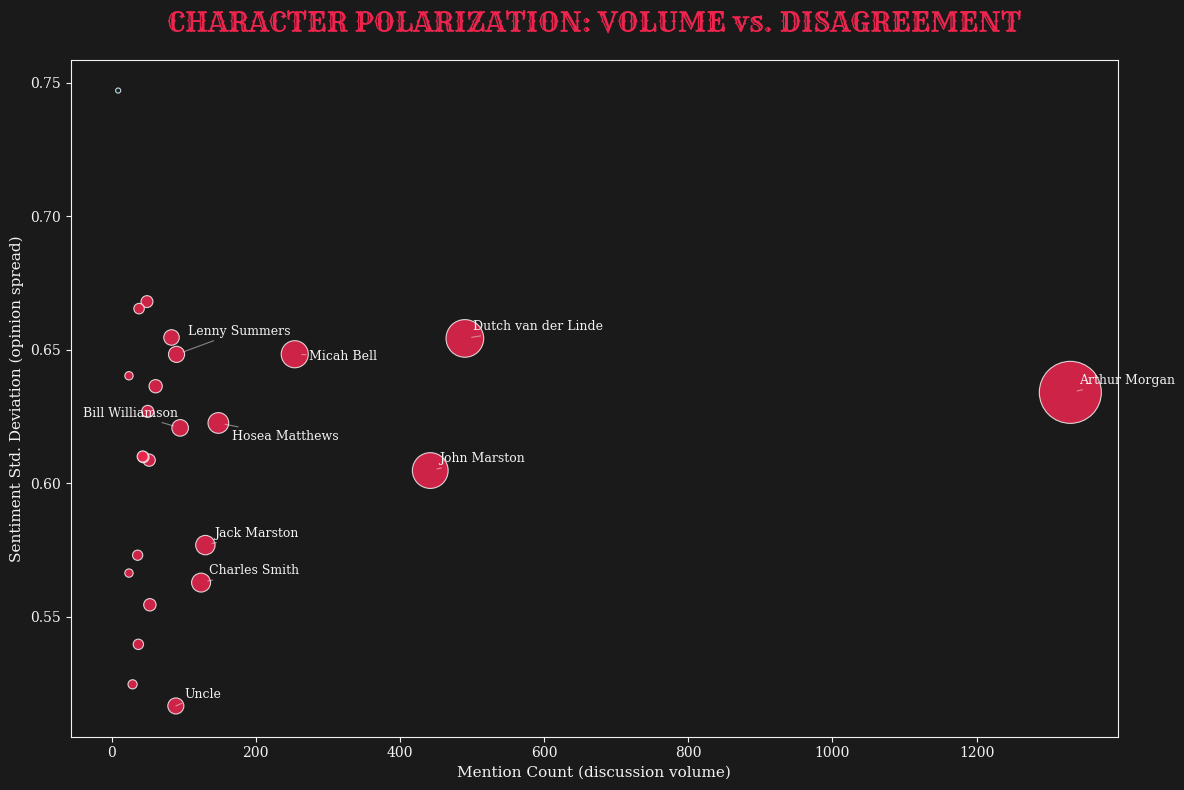

In [7]:
fig, ax = plt.subplots(figsize=(12, 8))

sizes = df_characters["mention_count"] * 1.5
colors = [COLOR_ACCENT if conf == False else COLOR_DARK_ACCENT for conf in df_characters["low_confidence"]]

ax.scatter(df_characters["mention_count"], df_characters["sentiment_std"], s=sizes, color=colors, edgecolor=COLOR_TEXT, linewidth=0.8, alpha=0.85)

top_labeled = df_characters.sort_values("mention_count", ascending=False).head(10)

label_offsets = {
    "Lenny Summers": (8, 14),
    "Micah Bell": (10, -4),
    "Hosea Matthews": (10, -12),
    "Bill Williamson": (-70, 8),
}

for _, row in top_labeled.iterrows():
    offset = label_offsets.get(row["entity_name"], (6, 6))
    ax.annotate(
        row["entity_name"],
        xy=(row["mention_count"], row["sentiment_std"]),
        xytext=offset, textcoords="offset points",
        fontsize=9, color=COLOR_TEXT,
        arrowprops=dict(arrowstyle="-", color=COLOR_TEXT, alpha=0.5, linewidth=0.8, shrinkA=0, shrinkB=5)
    )

ax.set_title("CHARACTER POLARIZATION: VOLUME vs. DISAGREEMENT", fontproperties=title_font, fontsize=20, color=COLOR_ACCENT, pad=20)
ax.set_xlabel("Mention Count (discussion volume)", fontsize=11)
ax.set_ylabel("Sentiment Std. Deviation (opinion spread)", fontsize=11)

plt.tight_layout()
plt.savefig("../charts/q2_character_polarization_scatter.png", dpi=300, facecolor=fig.get_facecolor())
plt.show()

## Volume vs. Disagreement
This is the "discovered" polarization view: Dutch van der Linde and Micah Bell both show high sentiment_std (~0.65) at meaningfully high volume (490 and 254 mentions respectively), marking them as the most genuinely polarizing characters — not just "hated," but generating real disagreement among players. Arthur's large bubble reflects volume more than true polarization, since his average sentiment is solidly positive.

**A note on this metric's fragility:** sorting purely by sentiment_std (without a volume floor) surfaces low-mention characters like Mary Linton (9 mentions) or Javier Escuella (49 mentions) ahead of Dutch/Micah — their extreme scores are small-sample noise, not genuine polarization signal. The "Dutch and Micah" finding specifically depends on restricting to characters with meaningfully high volume (≥100 mentions), not just clearing the 20-mention low_confidence threshold. Two polarization metrics were deliberately kept separate in the underlying data (raw = volume × disagreement, per-mention = disagreement alone) since "polarizing" has no single agreed definition.

# Question 3: How has sentiment toward RDR2 shifted over time, and what drove it?

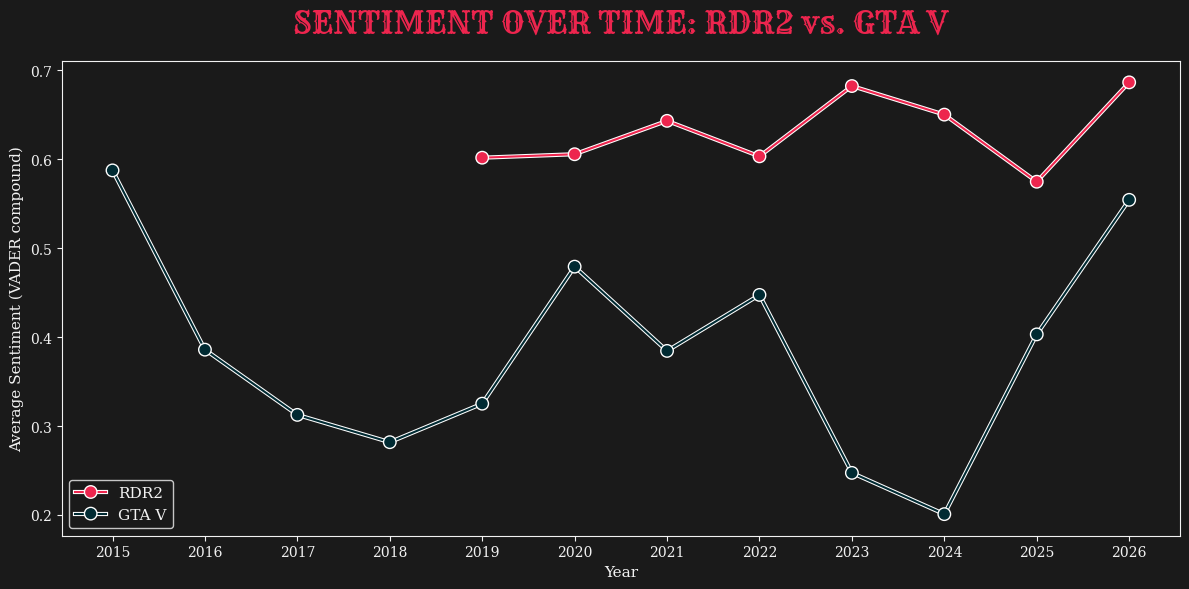

In [8]:
import matplotlib.patheffects as pe

fig, ax = plt.subplots(figsize=(12, 6))

for game, color in [("RDR2", COLOR_ACCENT), ("GTA V", COLOR_DARK_ACCENT)]:
    subset = df_yearly[df_yearly["game"] == game].sort_values("year")
    ax.plot(
        subset["year"], subset["avg_sentiment"],
        marker="o", linewidth=1.5, markersize=7, color=color, label=game,
        path_effects=[pe.Stroke(linewidth=3., foreground="white"), pe.Normal()]
    )

ax.set_title("SENTIMENT OVER TIME: RDR2 vs. GTA V", fontproperties=title_font, fontsize=22, color=COLOR_ACCENT, pad=20)
ax.set_ylabel("Average Sentiment (VADER compound)", fontsize=11)
ax.set_xlabel("Year", fontsize=11)
ax.legend(loc="lower left", fontsize=11, facecolor=COLOR_BG, edgecolor=COLOR_TEXT, labelcolor=COLOR_TEXT)
ax.set_xticks(df_yearly["year"].unique())

plt.tight_layout()
plt.savefig("../charts/q3_sentiment_over_time.png", dpi=300, facecolor=fig.get_facecolor())
plt.show()

## Sentiment Over Time: RDR2 vs. GTA V
RDR2 shows legacy inflation overall: sentiment has trended upward since 2019 launch (~0.60 → ~0.69), **despite a dip in 2025 (0.57)** — the path isn't a smooth climb, but the overall direction is upward, suggesting the game has aged well rather than souring in retrospect. GTA V is far more volatile throughout (swinging 0.20–0.59), consistent with it being a live-service game whose sentiment reacts to ongoing content/monetization events rather than reflecting a fixed, finished product.

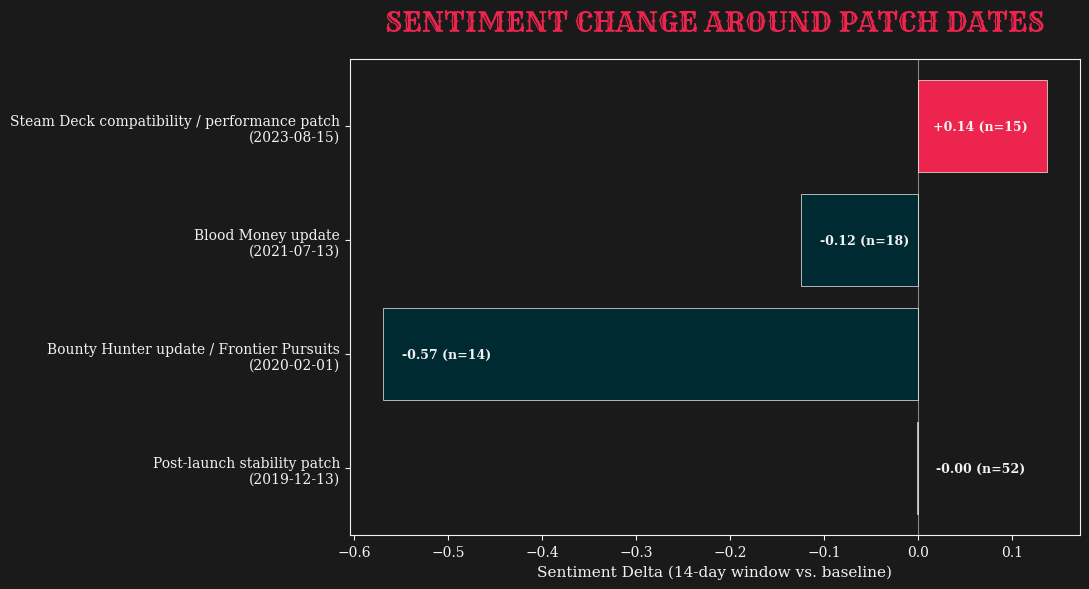

In [13]:
# Exclude the PC launch row - 0 reviews fell in that window (the earliest
# reviews in the dataset start slightly after this date), so there's nothing to plot.
df_patches_plot = df_patch_effects.dropna(subset=["sentiment_delta"]).copy()
df_patches_plot["label"] = df_patches_plot["description"] + "\n(" + df_patches_plot["patch_date"] + ")"

fig, ax = plt.subplots(figsize=(11, 6))

colors = [COLOR_ACCENT if d >= 0 else COLOR_DARK_ACCENT for d in df_patches_plot["sentiment_delta"]]
bars = ax.barh(df_patches_plot["label"], df_patches_plot["sentiment_delta"], color=colors, edgecolor=COLOR_TEXT, linewidth=0.5)

ax.set_title("SENTIMENT CHANGE AROUND PATCH DATES", fontproperties=title_font, fontsize=20, color=COLOR_ACCENT, pad=20)
ax.set_xlabel("Sentiment Delta (14-day window vs. baseline)", fontsize=11)
ax.axvline(0, color=COLOR_TEXT, linewidth=0.8, alpha=0.5)

# Labels are placed INSIDE each bar, inset from its outer tip, so they never
# collide with the y-axis category labels regardless of how long the bar is
# (the original outside-the-tip placement overlapped the axis text for the
# longest bar, since its tip sat very close to the plot's left edge).
for bar, delta, n in zip(bars, df_patches_plot["sentiment_delta"], df_patches_plot["reviews_in_window"]):
    bar_width = bar.get_width()
    inset = 0.02
    if delta >= 0:
        label_x = bar_width - inset
        ha = "right"
    else:
        label_x = bar_width + inset
        ha = "left"
    ax.text(label_x, bar.get_y() + bar.get_height()/2, f"{delta:+.2f} (n={int(n)})",
             va="center", ha=ha, fontsize=9, color=COLOR_TEXT, weight="bold")

plt.tight_layout()
plt.savefig("../charts/q3_patch_date_effects.png", dpi=300, facecolor=fig.get_facecolor())
plt.show()

## Sentiment Change Around Patch Dates — attempted, inconclusive
Tests whether sentiment shifts measurably in the ~2 weeks following major patches/updates. **Result: sample sizes per window (14–18 reviews) are too small to trust as a signal** — the "Bounty Hunter update" window shows a dramatic -0.57 swing on just 14 reviews, almost certainly noise rather than a genuine patch reaction; a swing that large from such a small sample isn't distinguishable from random variation in review timing (e.g. a few negative reviews about an unrelated recurring issue like DRM/Social Club connectivity happening to land in that window).

This is included here as a **documented limitation, not a hidden gap**: the analysis was run, the data collected, and the conclusion is genuinely "we can't say" rather than omitted silently. The PC launch date itself has zero reviews in-window, since the earliest reviews in the historical dataset begin slightly after that date.

# Question 4: How does RDR2 compare to GTA V on reception and engagement?

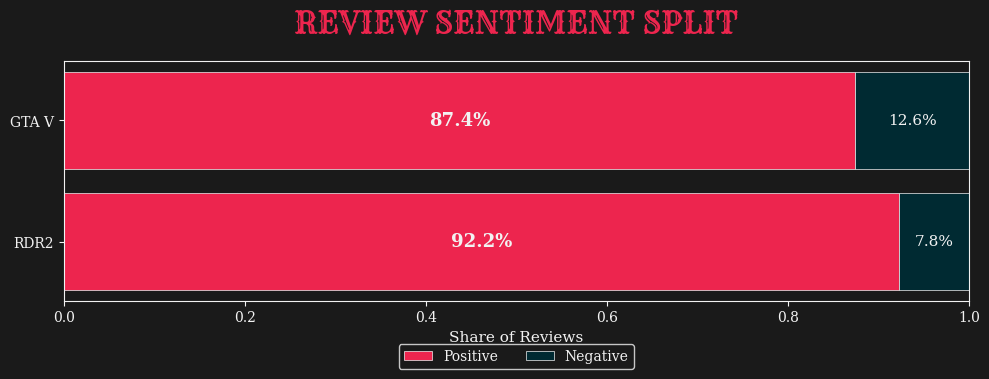

In [10]:
fig, ax = plt.subplots(figsize=(10, 4))

pos_ratio = df_comparison["positive_reviews"] / (df_comparison["positive_reviews"] + df_comparison["negative_reviews"])
neg_ratio = 1 - pos_ratio

ax.barh(df_comparison["game"], pos_ratio, color=COLOR_ACCENT, edgecolor=COLOR_TEXT, linewidth=0.5, label="Positive")
ax.barh(df_comparison["game"], neg_ratio, left=pos_ratio, color=COLOR_DARK_ACCENT, edgecolor=COLOR_TEXT, linewidth=0.5, label="Negative")

for i, (game, pos, neg) in enumerate(zip(df_comparison["game"], pos_ratio, neg_ratio)):
    ax.text(pos/2, i, f"{pos:.1%}", ha="center", va="center", fontsize=13, color=COLOR_TEXT, weight="bold")
    ax.text(pos + neg/2, i, f"{neg:.1%}", ha="center", va="center", fontsize=11, color=COLOR_TEXT)

ax.set_title("REVIEW SENTIMENT SPLIT", fontproperties=title_font, fontsize=22, color=COLOR_ACCENT, pad=20)
ax.set_xlim(0, 1)
ax.set_xlabel("Share of Reviews", fontsize=11)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=2, fontsize=10, facecolor=COLOR_BG, edgecolor=COLOR_TEXT, labelcolor=COLOR_TEXT)

plt.tight_layout()
plt.savefig("../charts/q4_positive_review_ratio.png", dpi=300, facecolor=fig.get_facecolor())
plt.show()

## Review Sentiment Split
RDR2 has a higher positive-review ratio (92.2%) than GTA V (87.4%) — despite GTA V having far more total reviews, RDR2's audience is proportionally more consistently satisfied.

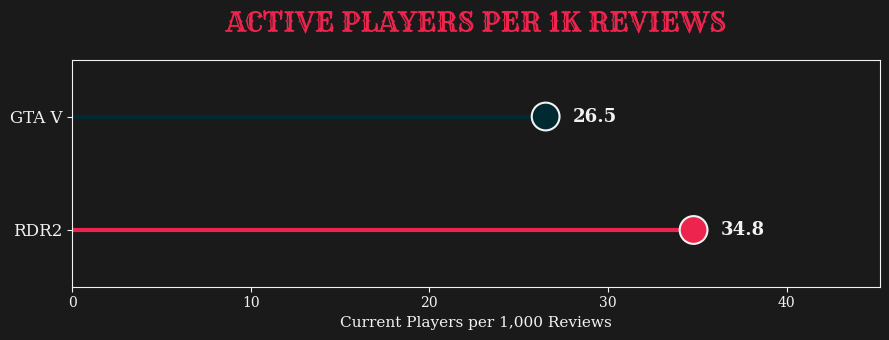

In [11]:
fig, ax = plt.subplots(figsize=(9, 3.5))

y_pos = [0, 1]
colors = [COLOR_ACCENT, COLOR_DARK_ACCENT]

ax.hlines(y=y_pos, xmin=0, xmax=df_comparison["players_per_1k_reviews"], color=colors, linewidth=3)
ax.scatter(df_comparison["players_per_1k_reviews"], y_pos, color=colors, s=400, zorder=3, edgecolor=COLOR_TEXT, linewidth=1.5)

for i, val in zip(y_pos, df_comparison["players_per_1k_reviews"]):
    ax.text(val + 1.5, i, f"{val:.1f}", va="center", fontsize=13, color=COLOR_TEXT, weight="bold")

ax.set_yticks(y_pos)
ax.set_yticklabels(df_comparison["game"], fontsize=12)
ax.set_ylim(-0.5, 1.5)
ax.set_title("ACTIVE PLAYERS PER 1K REVIEWS", fontproperties=title_font, fontsize=20, color=COLOR_ACCENT, pad=20)
ax.set_xlabel("Current Players per 1,000 Reviews", fontsize=11)
ax.set_xlim(0, max(df_comparison["players_per_1k_reviews"]) * 1.3)

plt.tight_layout()
plt.savefig("../charts/q4_players_per_1k_reviews.png", dpi=300, facecolor=fig.get_facecolor())
plt.show()

## Active Players per 1K Reviews
RDR2 shows a stronger ratio (34.8) than GTA V (26.5) — a retention-relative-to-reviews proxy suggesting RDR2 retains proportionally more of its reviewing audience as active players today. Important framing caveat: this is a ratio, not raw scale — GTA V still has far more total concurrent players in absolute terms.

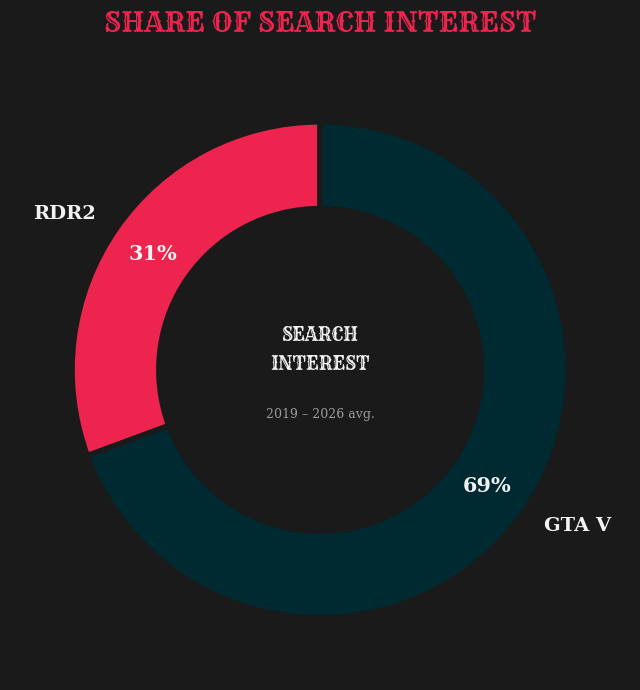

In [12]:
fig, ax = plt.subplots(figsize=(7, 7))

game_labels = df_trends_summary["game"].replace({"Red Dead Redemption 2": "RDR2"}).tolist()
values = df_trends_summary["avg_search_interest"].tolist()

wedges, texts, autotexts = ax.pie(
    values, labels=game_labels, colors=[COLOR_ACCENT, COLOR_DARK_ACCENT],
    autopct=lambda p: f"{p:.0f}%", startangle=90,
    wedgeprops=dict(width=0.35, edgecolor=COLOR_BG, linewidth=4),
    pctdistance=0.82,
    textprops={"fontsize": 14, "color": COLOR_TEXT}
)
for autotext in autotexts:
    autotext.set_fontsize(15)
    autotext.set_weight("bold")
for text in texts:
    text.set_fontsize(14)
    text.set_weight("bold")

ax.text(0, 0.08, "SEARCH\nINTEREST", ha="center", va="center", fontsize=13, color=COLOR_TEXT,
        fontproperties=title_font, linespacing=1.6)
ax.text(0, -0.18, "2019 \u2013 2026 avg.", ha="center", va="center", fontsize=9, color=COLOR_TEXT, alpha=0.6)

ax.set_title("SHARE OF SEARCH INTEREST", fontproperties=title_font, fontsize=20, color=COLOR_ACCENT, pad=20)

plt.tight_layout()
plt.savefig("../charts/q4_search_interest.png", dpi=300, facecolor=fig.get_facecolor())
plt.show()

## Share of Search Interest
GTA V draws roughly 2.3x RDR2's average search interest on Google Trends' 0–100 index (33.1 vs. 14.6) — shown above as a 69%/31% share-of-combined-interest split, almost certainly driven by its live-service model (ongoing GTA Online content) and broader cultural presence, versus RDR2 being a complete, self-contained experience with no ongoing content cycle generating fresh search activity.

*Overall Q4 narrative*: GTA V wins on scale and search relevance due to its live-service nature; RDR2 wins on relative audience satisfaction and retention as a finished, self-contained narrative experience.